# Disaster Tweet Classification - EDA and Machine Learning
**Goal:** classify a tweet as a real disaster (1) or not (0).  
**Dataset:** `data/twitter_disaster_dataset.csv` (7,613 hand-labelled tweets; the task PDF mentions ~10,000).  
**Notebook order:** 1. Load & explore -> 2. Clean & prepare -> 3. Features -> 4. Model comparison (cross-validation) -> 5. Final evaluation -> 6. Interpretation -> 7. Limitations.

> Run this notebook from inside the `notebooks/` folder with the `disaster_tweets` kernel. The long hyper-parameter search lives in `src/train.py`; this notebook shows its results and re-checks the saved model.

In [4]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
raw = pd.read_csv(r"C:\Users\rhndu\Downloads\disaster_tweets\disaster_tweets\data\twitter_disaster_dataset.csv")
raw.head()

,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1


In [9]:

import sys
import warnings
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Set the project root folder
PROJECT_ROOT = Path(
    r"C:\Users\rhndu\Downloads\disaster_tweets\disaster_tweets"
)

# Allow Python to find the src package
sys.path.insert(0, str(PROJECT_ROOT))

# Import preprocessing functions
from src.preprocess import (
    load_and_clean_data,
    clean_text,
    tokenize,
    extra_features,
    get_train_test
)

# Define the dataset path separately
DATA_PATH = PROJECT_ROOT / "data" / "twitter_disaster_dataset.csv"

# Load the dataset
raw = pd.read_csv(DATA_PATH)

# Display the first five rows
raw.head()


ModuleNotFoundError: No module named 'vaderSentiment'

In [3]:
import sys, warnings
sys.path.append("..")            # so we can import from src/
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from collections import Counter
sns.set_theme(style="whitegrid")
from src.preprocess import (load_and_clean_data, clean_text, tokenize, extra_features,
                            get_train_test, DATA_PATH)
raw = pd.read_csv(DATA_PATH)
raw.head()

ModuleNotFoundError: No module named 'vaderSentiment'

## 1. Data exploration
### 1.1 Structure, data types, missing values, duplicates

In [5]:
print("Shape:", raw.shape)
print(raw.dtypes, "\n")
print("Missing values:\n", raw.isna().sum(), "\n")
print("Fully duplicated rows:", raw.duplicated().sum())
print("Rows whose tweet text appears more than once:", raw.duplicated('text').sum())
conf = raw[raw.duplicated('text', keep=False)].groupby('text').target.nunique()
print("Duplicate texts with CONFLICTING labels:", (conf > 1).sum())

Shape: (7613, 5)
id           int64
keyword     object
location    object
text        object
target       int64
dtype: object 

Missing values:
 id             0
keyword       61
location    2534
text           0
target         0
dtype: int64 

Fully duplicated rows: 0
Rows whose tweet text appears more than once: 110
Duplicate texts with CONFLICTING labels: 18


**Findings:** 5 columns (`id`, `keyword`, `location`, `text`, `target`). `keyword` has 61 and `location` 2,534 missing values. There are no fully duplicated rows, but 110 tweets repeat and 18 of those carry *conflicting* labels (label noise). We drop the conflicting ones and keep one copy of the other repeats so the same tweet can never sit in both train and test.

### 1.2 Class distribution

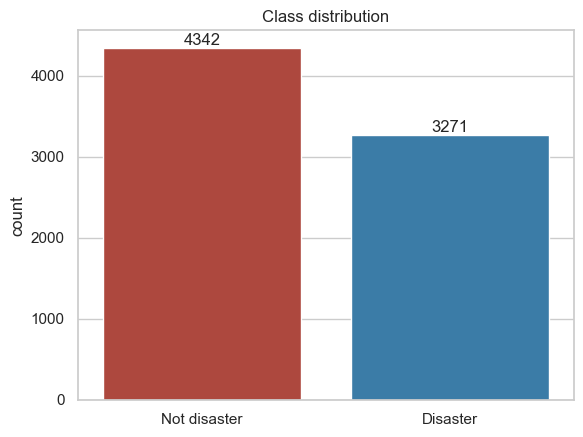

target
0    0.57
1    0.43
Name: proportion, dtype: float64


In [6]:
lab = raw.target.map({0: "Not disaster", 1: "Disaster"})
ax = sns.countplot(x=lab, hue=lab, order=["Not disaster","Disaster"], legend=False, palette=["#2980b9","#c0392b"])
for p in ax.patches: ax.annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.title("Class distribution"); plt.xlabel(""); plt.show()
print(raw.target.value_counts(normalize=True).round(3))

**Finding:** 57% not-disaster vs 43% disaster - mildly imbalanced. Not severe enough to need resampling, but we split with *stratification* and judge models by precision, recall and F1, not accuracy alone.

### 1.3 Label noise removal

In [8]:

import sys
from pathlib import Path

PROJECT_ROOT = Path(
    r"C:\Users\rhndu\Downloads\disaster_tweets\disaster_tweets"
)

sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocess import load_and_clean_data

print("Function imported successfully!")


ModuleNotFoundError: No module named 'vaderSentiment'

In [7]:
df = load_and_clean_data()
df["char_len"] = df.text.str.len(); df["n_hashtags"] = df.text.str.count("#")
df["n_mentions"] = df.text.str.count("@"); df["has_url"] = df.text.str.contains("http").astype(int)
df["label"] = df.target.map({0: "Not disaster", 1: "Disaster"})
df.shape

NameError: name 'load_and_clean_data' is not defined

### 1.4 Simple text characteristics by class

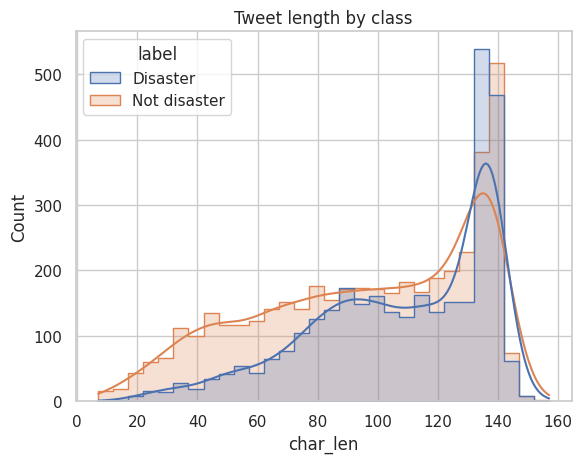

,char_len,n_hashtags,n_mentions,has_url
label,,,,
Disaster,108.008,0.515,0.28,0.673
Not disaster,95.559,0.384,0.43,0.417


In [ ]:
sns.histplot(data=df, x="char_len", hue="label", bins=30, kde=True, element="step")
plt.title("Tweet length by class"); plt.show()
df.groupby("label")[["char_len","n_hashtags","n_mentions","has_url"]].mean().round(3)

**Finding:** Disaster tweets are slightly longer and far more likely to contain a URL (news links) and hashtags; non-disaster tweets contain more @mentions (conversation). These weak signals motivated the 'extra features' experiment in section 4.

### 1.5 Most frequent words and phrases

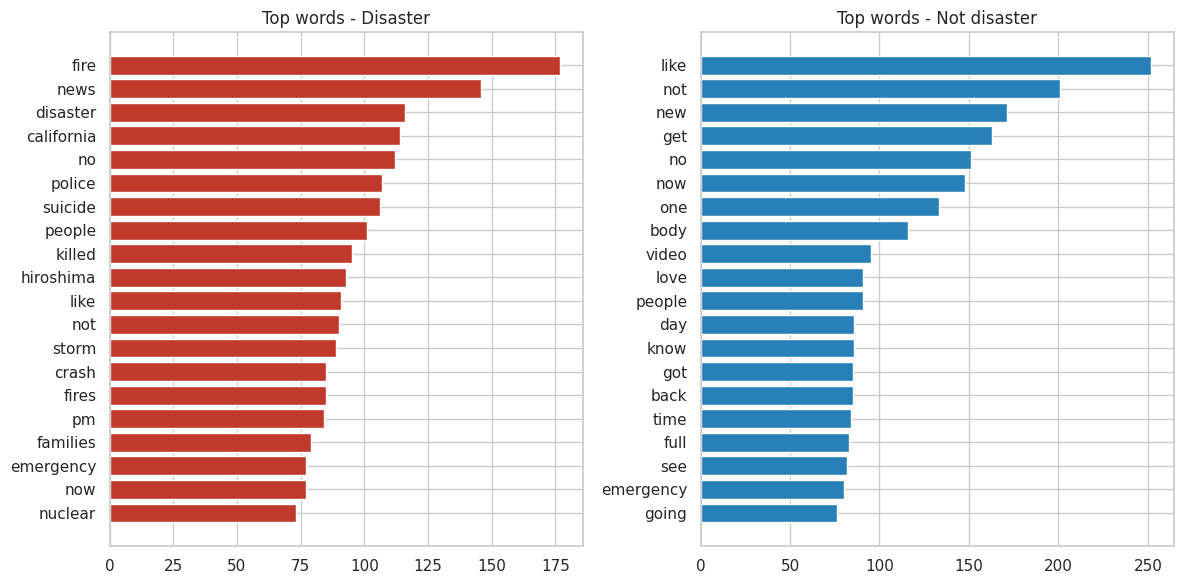

,bigram,count
0,suicide bomber,54
1,northern california,41
2,oil spill,38
3,suicide bombing,34
4,california wildfire,34
5,homes razed,29
6,burning buildings,28
7,latest homes,28
8,razed northern,28
9,confirmed mh,27


In [ ]:
def top_words(texts, n=20):
    c = Counter()
    for t in texts: c.update(tokenize(t))
    return c.most_common(n)
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, (lab_, col) in zip(axes, [(1,"#c0392b"),(0,"#2980b9")]):
    w, f = zip(*top_words(df[df.target==lab_].text))
    ax.barh(w[::-1], f[::-1], color=col); ax.set_title("Top words - " + ("Disaster" if lab_ else "Not disaster"))
plt.tight_layout(); plt.show()

bg = Counter()
for t in df[df.target==1].text:
    tk = tokenize(t); bg.update(f"{a} {b}" for a, b in zip(tk, tk[1:]))
pd.DataFrame(bg.most_common(15), columns=["bigram","count"])

**Finding:** Disaster tweets are dominated by event words (`fire`, `disaster`, `california`, `police`, `killed`, `storm`, `nuclear`) and phrases such as *suicide bomber*, *oil spill*, *northern california*. Non-disaster tweets use everyday words (`like`, `new`, `love`, `day`). Note that `fire`, `crash` and `body` appear in both worlds - this is the ambiguity the model has to resolve from context, and a reason to use word pairs (bigrams).

### 1.6 `keyword` / `location` and data leakage

In [ ]:
print(raw.groupby(raw.keyword.isna()).target.mean().round(3).rename({False:"keyword present", True:"keyword missing"}))

keyword
keyword present    0.428
keyword missing    0.689
Name: target, dtype: float64


**Finding - important:** only 43% of tweets with a keyword are disasters, but **69%** of tweets with a *missing* keyword are. That reflects how the dataset was collected, not anything about the tweet itself, and a user typing a tweet into the app has no such field. `keyword` and `location` are therefore **not used as model inputs** (potential leakage); the model reads the tweet text only.

## 2. Data preparation
Cleaning: lower-case, remove URLs, @mentions, special characters, digits and punctuation (hashtag word kept). Tokenisation: split into words, remove stop words (using our own list - scikit-learn's built-in list contains *fire*!).

In [ ]:
for t in ["Forest fire near La Ronge Sask. Canada http://t.co/abc #wildfire @user",
          "13,000 people receive #wildfires evacuation orders in California"]:
    print(t); print("  clean ->", clean_text(t)); print("  tokens->", tokenize(t), "\n")

Forest fire near La Ronge Sask. Canada http://t.co/abc #wildfire @user
  clean -> forest fire near la ronge sask canada wildfire
  tokens-> ['forest', 'fire', 'near', 'la', 'ronge', 'sask', 'canada', 'wildfire'] 

13,000 people receive #wildfires evacuation orders in California
  clean -> people receive wildfires evacuation orders in california
  tokens-> ['people', 'receive', 'wildfires', 'evacuation', 'orders', 'california'] 



In [ ]:
X_train, X_test, y_train, y_test = get_train_test(df)   # stratified 80/20, random_state=42
print(len(X_train), "train /", len(X_test), "test")
print("Disaster share  train: %.3f   test: %.3f" % (y_train.mean(), y_test.mean()))

5988 train / 1497 test
Disaster share  train: 0.426   test: 0.426


Target labels were already numeric (0 = not disaster, 1 = disaster). The test set is locked away until the final evaluation; the vectoriser is fitted **inside** the pipeline so it only ever learns from training folds (no leakage).

## 3. Feature engineering
* **TF-IDF** on word unigrams + bigrams (main features)
* **Extra features:** character length, word count, hashtags, mentions, URLs, exclamation mark, **VADER sentiment** score
* Pre-trained Word2Vec/GloVe: listed as 'consider' in the task; not used - they need a large download and gave no clear benefit expected for short, slang-heavy tweets, so we kept the pipeline light and easy to deploy.

In [ ]:
pd.DataFrame(extra_features(X_train.head(5)), columns=["char_len","word_count","n_hashtags","n_mentions","n_urls","has_exclaim","vader_compound"]).assign(text=X_train.head(5).values)

,char_len,word_count,n_hashtags,n_mentions,n_urls,has_exclaim,vader_compound,text
0,69.0,14.0,0.0,0.0,0.0,0.0,-0.7959,i miss my longer hair..but it was so dead anyw...
1,137.0,24.0,0.0,0.0,0.0,0.0,0.8934,The Riddler would be the best early-exit prima...
2,55.0,10.0,0.0,0.0,0.0,0.0,-0.4215,Remember how Nora Jones crushed it in Two Week...
3,81.0,11.0,0.0,0.0,1.0,1.0,0.0000,Here we go again. EBOLA! Run for your lives! a...
4,138.0,18.0,0.0,1.0,2.0,0.0,-0.8271,See the 16yr old PKK suicide bomber who detona...


## 4. Model comparison (5-fold stratified cross-validation, training data only)
Candidates (all standard for sparse text features): Logistic Regression, Multinomial Naive Bayes, Linear SVM, Random Forest, and Logistic Regression + extra features.

In [ ]:
base = pd.read_csv("../reports/cv_baseline_comparison.csv", index_col=0)
base.round(4)

,accuracy,precision,recall,f1,roc_auc,f1_std,train_f1
Logistic Regression,0.8039,0.8367,0.6706,0.7444,0.8611,0.0149,0.8587
Multinomial Naive Bayes,0.8053,0.8606,0.6478,0.7391,0.8593,0.0080,0.8375
Linear SVM,0.7851,0.7605,0.7231,0.7412,0.8462,0.0093,0.9599
Random Forest,0.8009,0.8193,0.6843,0.7454,0.8501,0.0076,0.9862
Logistic Regression + extra features,0.7971,0.8024,0.6957,0.7450,0.8547,0.0112,0.8396


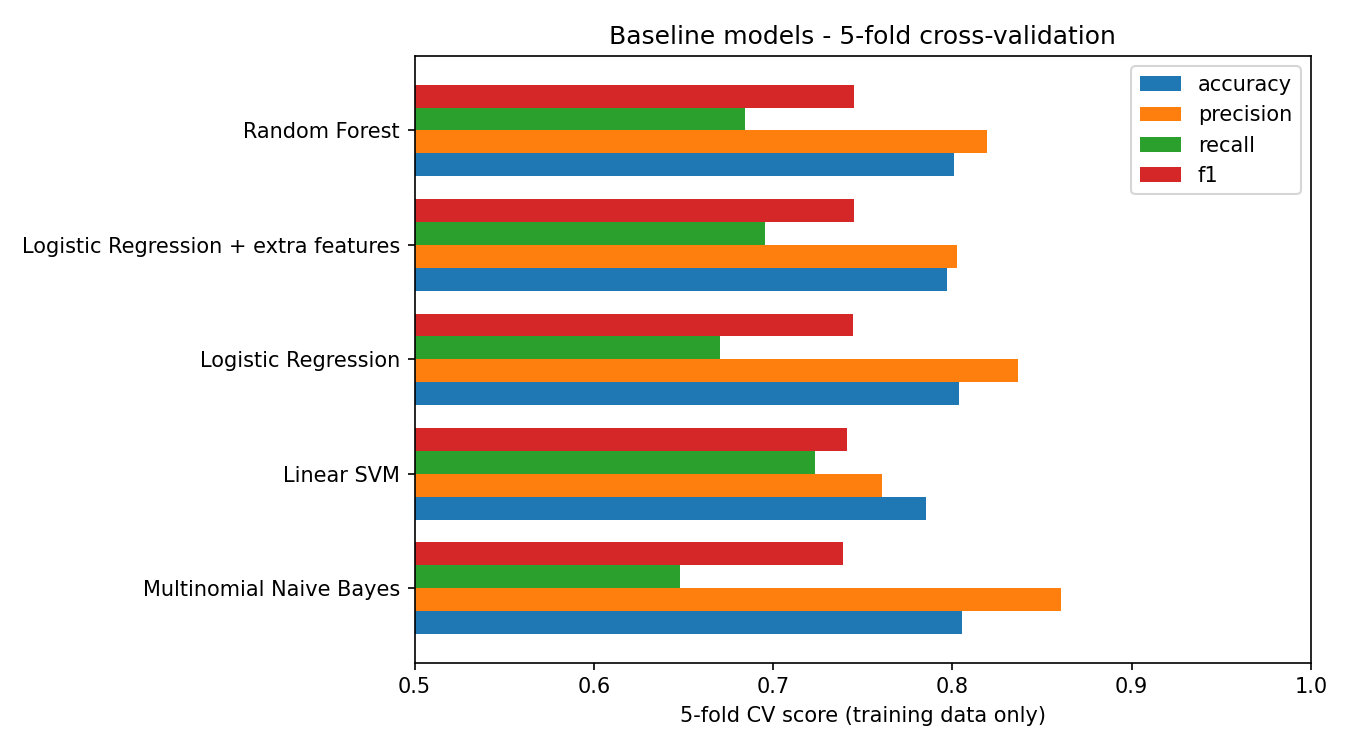

In [ ]:
from IPython.display import Image
Image("../reports/figures/cv_baseline.png")

**Hyper-parameter tuning** (GridSearchCV, scoring = F1, same 5 folds) was run for the two best baseline families.

In [ ]:
tuned = pd.read_csv("../reports/cv_tuned_comparison.csv", index_col=0)
tuned.round(4)

,accuracy,precision,recall,f1,roc_auc,f1_std,train_f1
Random Forest (tuned),0.7964,0.7953,0.7043,0.7468,0.8528,0.0135,0.8809
Logistic Regression (tuned),0.8073,0.8070,0.7196,0.7607,0.8622,0.0171,0.9825
Logistic Regression + extra features (tuned params),0.8046,0.7962,0.7278,0.7604,0.8642,0.0080,0.9752


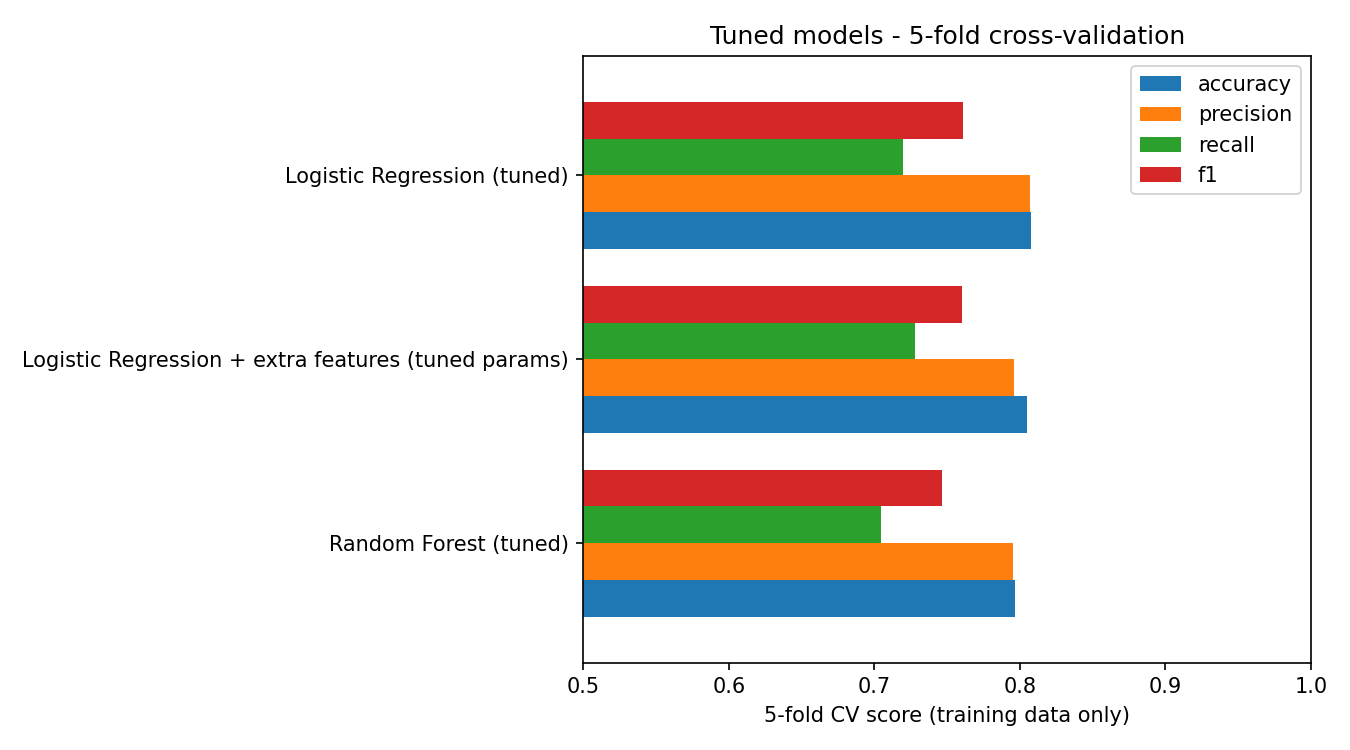

In [ ]:
Image("../reports/figures/cv_tuned.png")

**Reading the table:** the models are close (CV F1 roughly 0.74-0.76). Tuning helped Logistic Regression the most. Adding the hand-crafted features gave no clear gain (difference well within the fold-to-fold noise), so the simpler text-only model is kept.  
**Final model choice:** tuned **Logistic Regression** - highest (or within 0.005 of the highest) CV F1, it is fast, interpretable, and gives probabilities for the app.

## 5. Final evaluation on the held-out test set (used once)

In [ ]:
import joblib, json
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score, roc_curve,
                             precision_recall_curve, average_precision_score, f1_score)
model = joblib.load("../models/disaster_pipeline.joblib")
pred  = model.predict(X_test); score = model.predict_proba(X_test)[:, 1]
print(classification_report(y_test, pred, target_names=["Not disaster","Disaster"]))
print("ROC-AUC:", round(roc_auc_score(y_test, score), 3))
print("Train F1:", round(f1_score(y_train, model.predict(X_train)), 3), "| Test F1:", round(f1_score(y_test, pred), 3))

              precision    recall  f1-score   support

Not disaster       0.79      0.87      0.83       859
    Disaster       0.80      0.69      0.74       638

    accuracy                           0.79      1497
   macro avg       0.80      0.78      0.79      1497
weighted avg       0.80      0.79      0.79      1497

ROC-AUC: 0.846
Train F1: 0.98 | Test F1: 0.741


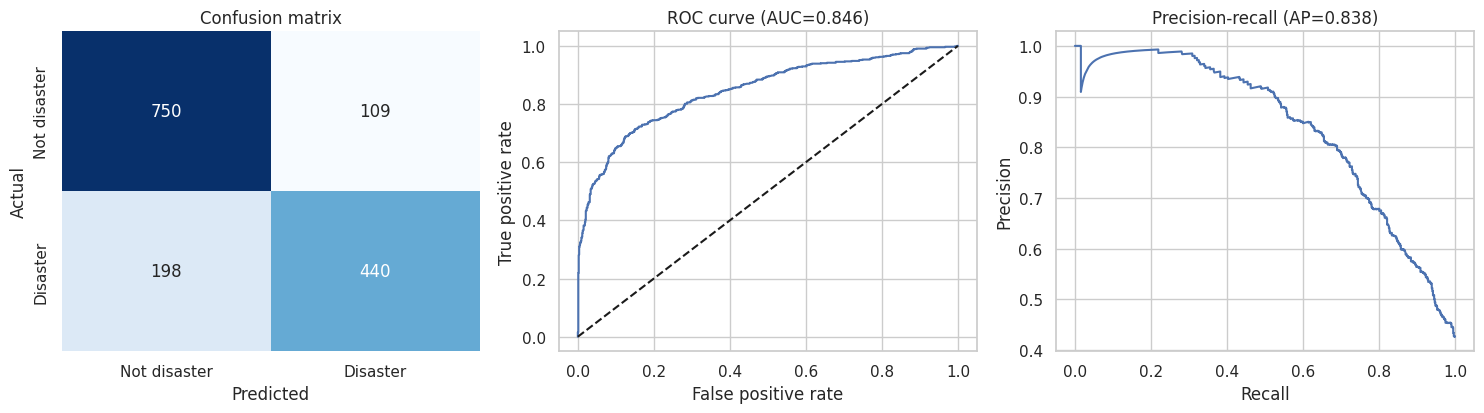

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0],
            xticklabels=["Not disaster","Disaster"], yticklabels=["Not disaster","Disaster"])
ax[0].set_title("Confusion matrix"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual")
fpr, tpr, _ = roc_curve(y_test, score); ax[1].plot(fpr, tpr); ax[1].plot([0,1],[0,1],"k--")
ax[1].set_title("ROC curve (AUC=%.3f)" % roc_auc_score(y_test, score)); ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate")
p, r, _ = precision_recall_curve(y_test, score); ax[2].plot(r, p)
ax[2].set_title("Precision-recall (AP=%.3f)" % average_precision_score(y_test, score)); ax[2].set_xlabel("Recall"); ax[2].set_ylabel("Precision")
plt.tight_layout(); plt.show()

**Interpretation (plain language):** on tweets it had never seen, the model is right about 79% of the time. When it says 'disaster' it is right about 80% of the time (precision), but it only catches about 69% of real disaster tweets (recall) - so it misses roughly 3 in 10 real ones.  
**Overfitting check:** F1 on the *training* data is ~0.98 versus ~0.76 in cross-validation and ~0.74 on the test set. The model partly memorises training tweets - typical for word-based models on ~6,000 tweets. The cross-validation and test scores are the honest ones; the small CV-test gap (~0.02) shows no further hidden leakage from model selection. More data, or fine-tuning a pre-trained language model, would be the next step to improve generalisation.

## 6. Model interpretation

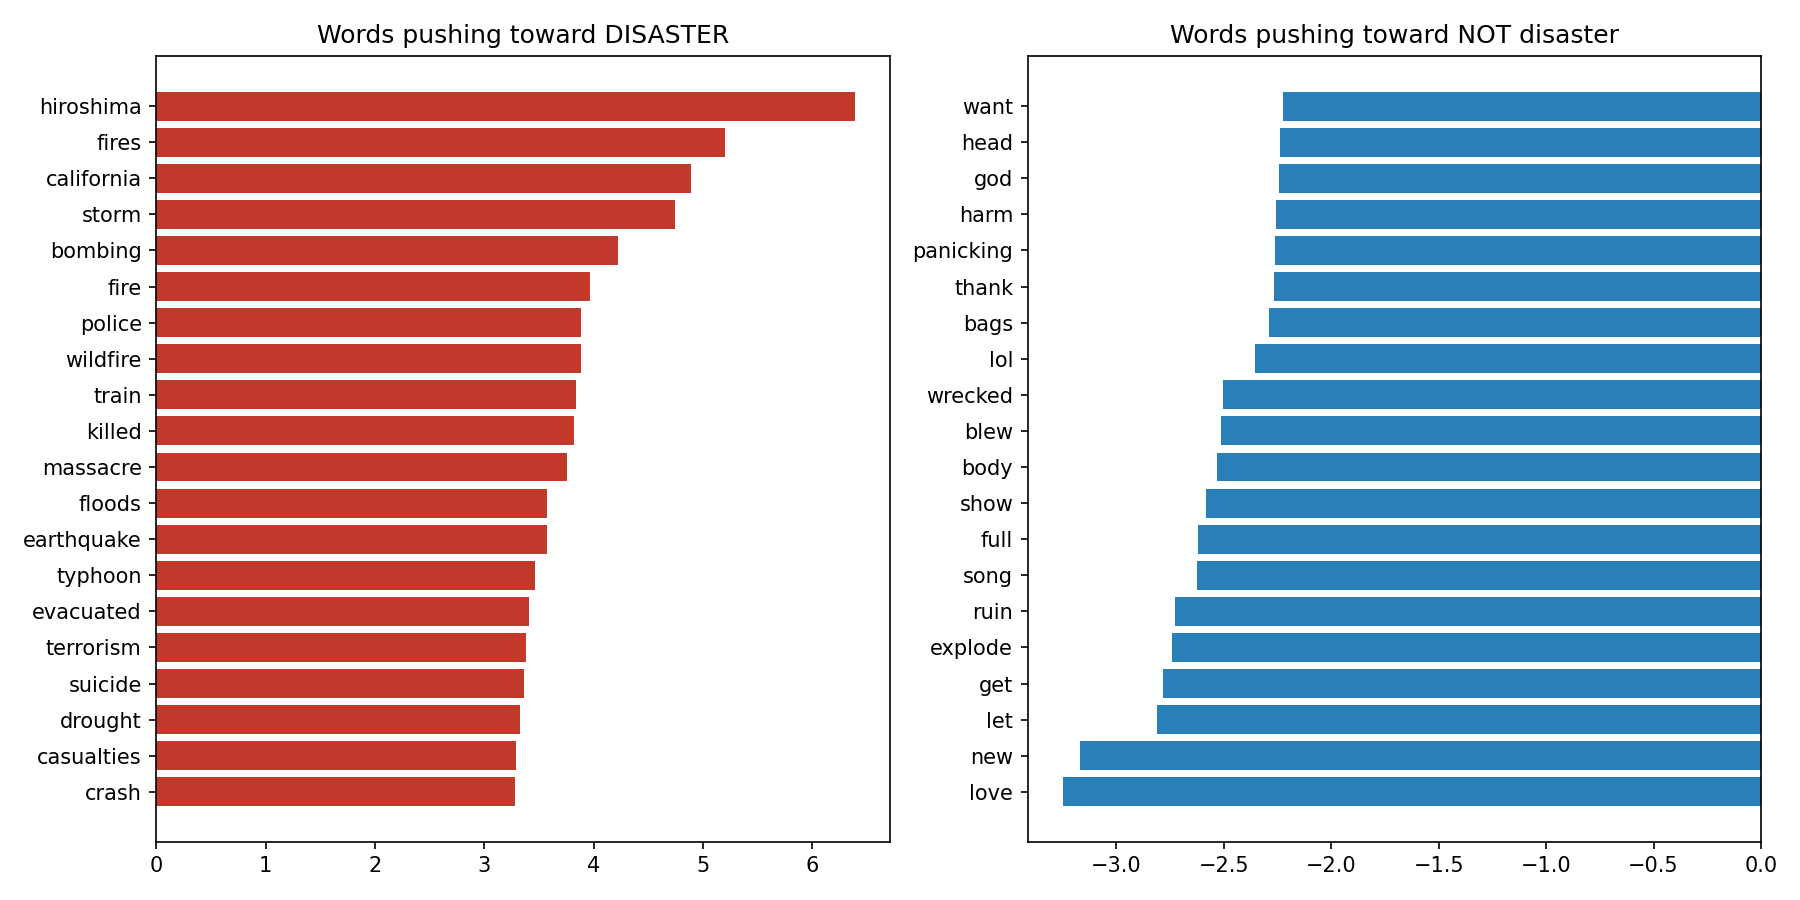

In [ ]:
Image("../reports/figures/top_features.png")

The strongest *disaster* words are event terms (e.g. hiroshima, california, storm, bombing, wildfire, killed, massacre, earthquake, typhoon, evacuated); the strongest *not-disaster* words are casual language (love, new, song, lol, thank) plus metaphor-style verbs such as explode, ruin, blew and wrecked. These are **associations learned from this dataset, not causes**.

In [ ]:
tests = ["Forest fire near La Ronge Sask. Canada", "That new song is fire, absolutely killing it tonight",
         "I'm gonna crash and burn on this exam tomorrow", "Just had a great pizza for lunch",
         "Earthquake of magnitude 6.1 hits near the coast, tsunami warning issued"]
pd.DataFrame({"tweet": tests, "P(disaster)": model.predict_proba(tests)[:,1].round(2), "prediction": model.predict(tests)})

,tweet,P(disaster),prediction
0,Forest fire near La Ronge Sask. Canada,0.90,1
1,"That new song is fire, absolutely killing it t...",0.23,0
2,I'm gonna crash and burn on this exam tomorrow,0.57,1
3,Just had a great pizza for lunch,0.23,0
4,Earthquake of magnitude 6.1 hits near the coas...,0.95,1


A handful of hand-written tweets is only a *qualitative* sanity check (not a performance estimate). Metaphorical uses (`crash and burn`) are the model's weak spot.

## 7. Limitations and recommendations
* The model only sees words - no images, links' content or user context; sarcasm and irony are hard.
* Labels were made by people and contain some noise; the data covers a limited time window/events, so new kinds of disasters may be recognised less well.
* Recall (~69%) means some real disasters are missed; for a real alert system, lower the decision threshold and accept more false alarms, or use it as a *triage* tool with human review.
* Near-duplicate tweets (retweets with small edits) may remain across train and test and could make the test score slightly optimistic.
* Next steps: more data, pre-trained transformer embeddings, threshold tuning, monitoring for drift.